# Random Forest - Palihakkara P. J. (IT25102047)


## 1. Model Suitability

**Why Random Forest?**

- Ensemble of many Decision Trees reduces variance and overfitting of a single tree.
- Excellent performance on tabular medical data.
- Built-in feature importance ranking.
- Handles non-linearities and feature interactions.
- Robust to outliers and does not require feature scaling.
- Provides probability estimates via averaging.


In [ ]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df['Class'].value_counts())
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (699, 20)
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
df = df.drop(columns=['Sample_code_number'], errors='ignore')
feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]
X_orig = df[feature_cols_orig].values
X_scaled = df[feature_cols_scaled].values
y = df['Class'].values
print("Original features shape:", X_orig.shape)
print("Scaled features shape  :", X_scaled.shape)
print("Class balance          :", np.bincount(y))

Original features shape: (699, 9)
Scaled features shape  : (699, 9)
Class balance          : [458 241]


In [ ]:
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)
X_train_scaled, X_test_scaled, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print("Train size:", X_train_orig.shape[0], "| Test size:", X_test_orig.shape[0])
print("Train class distribution:", np.bincount(y_train))

Train size: 559 | Test size: 140
Train class distribution: [366 193]


In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.0
    }
    print(f"\n========== {model_name} ==========")
    print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")
    return metrics, y_pred, y_prob

## 2. Implementation – Random Forest Varieties

| Variety | Description |
|---------|-------------|
| V1 Baseline | n_estimators=100, defaults |
| V2 Manual | n_estimators=200, max_depth=6, balanced |
| V3 GridSearchCV | Full hyperparameter search |
| V4 Scaled | Best params on scaled features |


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# V1 Baseline
rf_v1 = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
metrics_v1, y_pred_v1, y_prob_v1 = evaluate_model(
    rf_v1, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V1: Random Forest (Baseline n=100)"
)


========== V1: Random Forest (Baseline n=100) ==========
               precision    recall  f1-score   support

   Benign (0)       0.97      0.96      0.96        92
Malignant (1)       0.92      0.94      0.93        48

     accuracy                           0.95       140
    macro avg       0.94      0.95      0.94       140
 weighted avg       0.95      0.95      0.95       140

Confusion Matrix:
 [[88  4]
 [ 3 45]]
ROC-AUC: 0.9885


In [ ]:
# V2 Manual
rf_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
metrics_v2, y_pred_v2, y_prob_v2 = evaluate_model(
    rf_v2, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V2: Random Forest (Manual tuned)"
)


========== V2: Random Forest (Manual tuned) ==========
               precision    recall  f1-score   support

   Benign (0)       0.99      0.96      0.97        92
Malignant (1)       0.92      0.98      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.97      0.96       140
 weighted avg       0.97      0.96      0.96       140

Confusion Matrix:
 [[88  4]
 [ 1 47]]
ROC-AUC: 0.9916


In [ ]:
# V3 GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 3],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_rf.fit(X_train_orig, y_train)
print("Best parameters :", grid_rf.best_params_)
print("Best CV F1 score:", grid_rf.best_score_)

rf_v3 = grid_rf.best_estimator_
metrics_v3, y_pred_v3, y_prob_v3 = evaluate_model(
    rf_v3, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V3: Random Forest (GridSearchCV Best)"
)

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Best parameters : {'class_weight': 'balanced', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 score: 0.9623955666149758

========== V3: Random Forest (GridSearchCV Best) ==========
               precision    recall  f1-score   support

   Benign (0)       0.99      0.96      0.97        92
Malignant (1)       0.92      0.98      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.97      0.96       140
 weighted avg       0.97      0.96      0.96       140

Confusion Matrix:
 [[88  4]
 [ 1 47]]
ROC-AUC: 0.9900


In [ ]:
# V4 Best params on scaled features
rf_v4 = RandomForestClassifier(**grid_rf.best_params_, random_state=42, n_jobs=-1)
metrics_v4, y_pred_v4, y_prob_v4 = evaluate_model(
    rf_v4, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V4: Random Forest (Best params, Scaled)"
)


========== V4: Random Forest (Best params, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.99      0.96      0.97        92
Malignant (1)       0.92      0.98      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.97      0.96       140
 weighted avg       0.97      0.96      0.96       140

Confusion Matrix:
 [[88  4]
 [ 1 47]]
ROC-AUC: 0.9900


## 3. Comparison

In [ ]:
results_df = pd.DataFrame([metrics_v1, metrics_v2, metrics_v3, metrics_v4]).set_index('Model')
print(results_df.round(4).to_string())
print("\n>>> Best F1:", results_df['F1-Score'].idxmax(), f"({results_df['F1-Score'].max():.4f})")

                                         Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                                  
V1: Random Forest (Baseline n=100)         0.9500     0.9184  0.9375    0.9278   0.9885
V2: Random Forest (Manual tuned)           0.9643     0.9216  0.9792    0.9495   0.9916
V3: Random Forest (GridSearchCV Best)      0.9643     0.9216  0.9792    0.9495   0.9900
V4: Random Forest (Best params, Scaled)    0.9643     0.9216  0.9792    0.9495   0.9900

>>> Best F1: V2: Random Forest (Manual tuned) (0.9495)


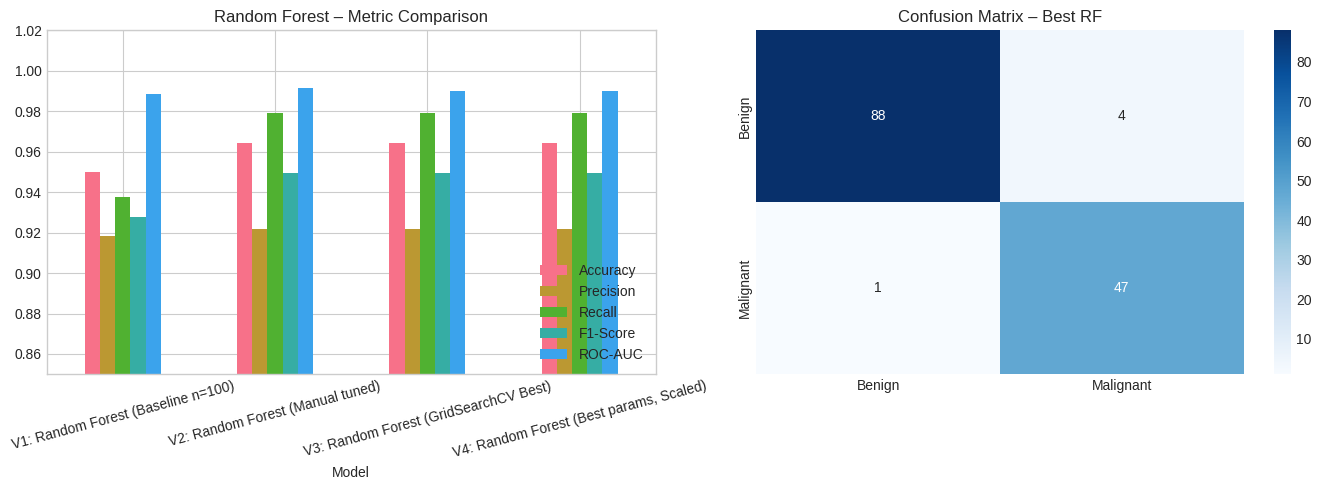

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
results_df[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_title('Random Forest – Metric Comparison')
axes[0].set_ylim(0.85, 1.02)
axes[0].legend(loc='lower right')
cm = confusion_matrix(y_test, y_pred_v3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[1].set_title('Confusion Matrix – Best RF')
plt.tight_layout()
plt.show()

                    Feature  Importance
    Uniformity_of_Cell_Size    0.358191
   Uniformity_of_Cell_Shape    0.215540
                Bare_Nuclei    0.133123
            Normal_Nucleoli    0.092515
Single_Epithelial_Cell_Size    0.091276
            Bland_Chromatin    0.056507
            Clump_Thickness    0.028504
          Marginal_Adhesion    0.021747
                    Mitoses    0.002597


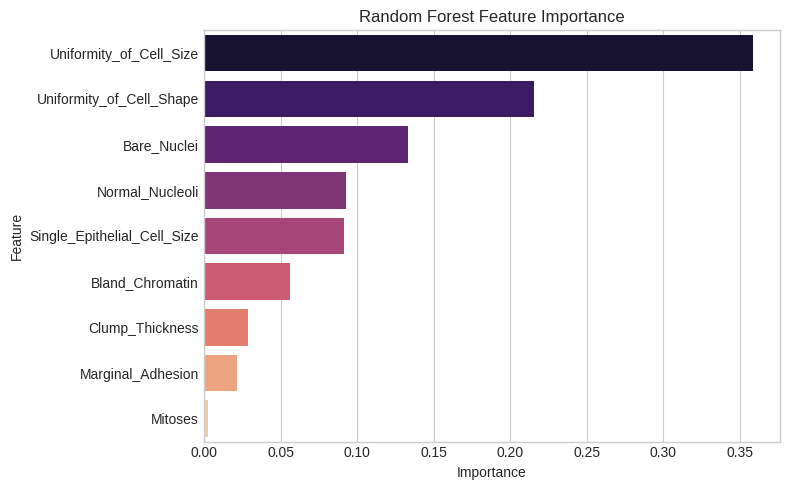

In [ ]:
# Feature Importance
imp_df = pd.DataFrame({
    'Feature': feature_cols_orig,
    'Importance': rf_v3.feature_importances_
}).sort_values('Importance', ascending=False)
print(imp_df.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=imp_df, x='Importance', y='Feature', palette='magma')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

## 4. Validation Method
Stratified 80/20 + Stratified 5-Fold CV, scoring = F1.

## 5. Conclusion
- Random Forest is one of the strongest performers on this dataset.
- Feature importance highlights Uniformity of Cell Size/Shape and Bare Nuclei.
- **Recommended**: Variety 3 (GridSearchCV best).

## 6. Limitations & Improvements
| Limitation | Improvement |
|------------|-------------|
| Less interpretable than single tree | Use SHAP / partial dependence |
| Memory & training time | Limit n_estimators / max_depth |
| Can still overfit noisy features | Feature selection |
